# 02 · Front-end check: torchaudio vs librosa

Training uses torchaudio only. librosa is the reference. This notebook runs `eval/feature_check.py` on 64 random ESC-50 clips with the baseline settings (22.05 kHz, n_fft 1024, hop 512, 64 Slaney mel bands, natural log with a 1e-6 offset) and records the difference.

**Tolerance:** the maximum absolute log-mel difference per clip must stay below **1e-3** (natural-log units, i.e. a 0.1% power ratio), over bins within 80 dB of the clip's maximum. Below that floor, float32 rounding in near-silent bins dominates; those bins are reported separately and are not part of the pass criterion.

In [1]:
import os, sys, json
from pathlib import Path
if Path.cwd().name == "notebooks":
    os.chdir("..")
sys.path.insert(0, "eval")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline
import feature_check

res = feature_check.run("configs/baseline.yaml", n=64, atol=1e-3, floor_db=-80.0, seed=0)
print(f"{res['n_clips']} clips | worst max |diff| = {res['worst_max_abs_diff']:.2e} | mean |diff| = {res['mean_of_mean_abs_diff']:.2e} | passed = {res['passed']}")
print("librosa", res["librosa"], "| torch", res["torch"])

64 clips | worst max |diff| = 1.96e-04 | mean |diff| = 8.99e-07 | passed = True
librosa 1.0.1 | torch 2.15.0+cu132


In [2]:
df = pd.DataFrame(res["clips"])
df[["max_abs_diff", "mean_abs_diff", "max_abs_diff_all_bins", "bins_checked_fraction"]].describe()

,max_abs_diff,mean_abs_diff,max_abs_diff_all_bins,bins_checked_fraction
count,64.000000,6.400000e+01,64.000000,64.000000
mean,0.000034,8.993209e-07,0.000035,0.917884
std,0.000038,4.958125e-07,0.000038,0.180798
min,0.000008,1.559993e-07,0.000008,0.181279
25%,0.000011,6.333645e-07,0.000011,0.999313
50%,0.000022,7.412712e-07,0.000022,1.000000
75%,0.000040,1.068137e-06,0.000041,1.000000
max,0.000196,2.814021e-06,0.000196,1.000000


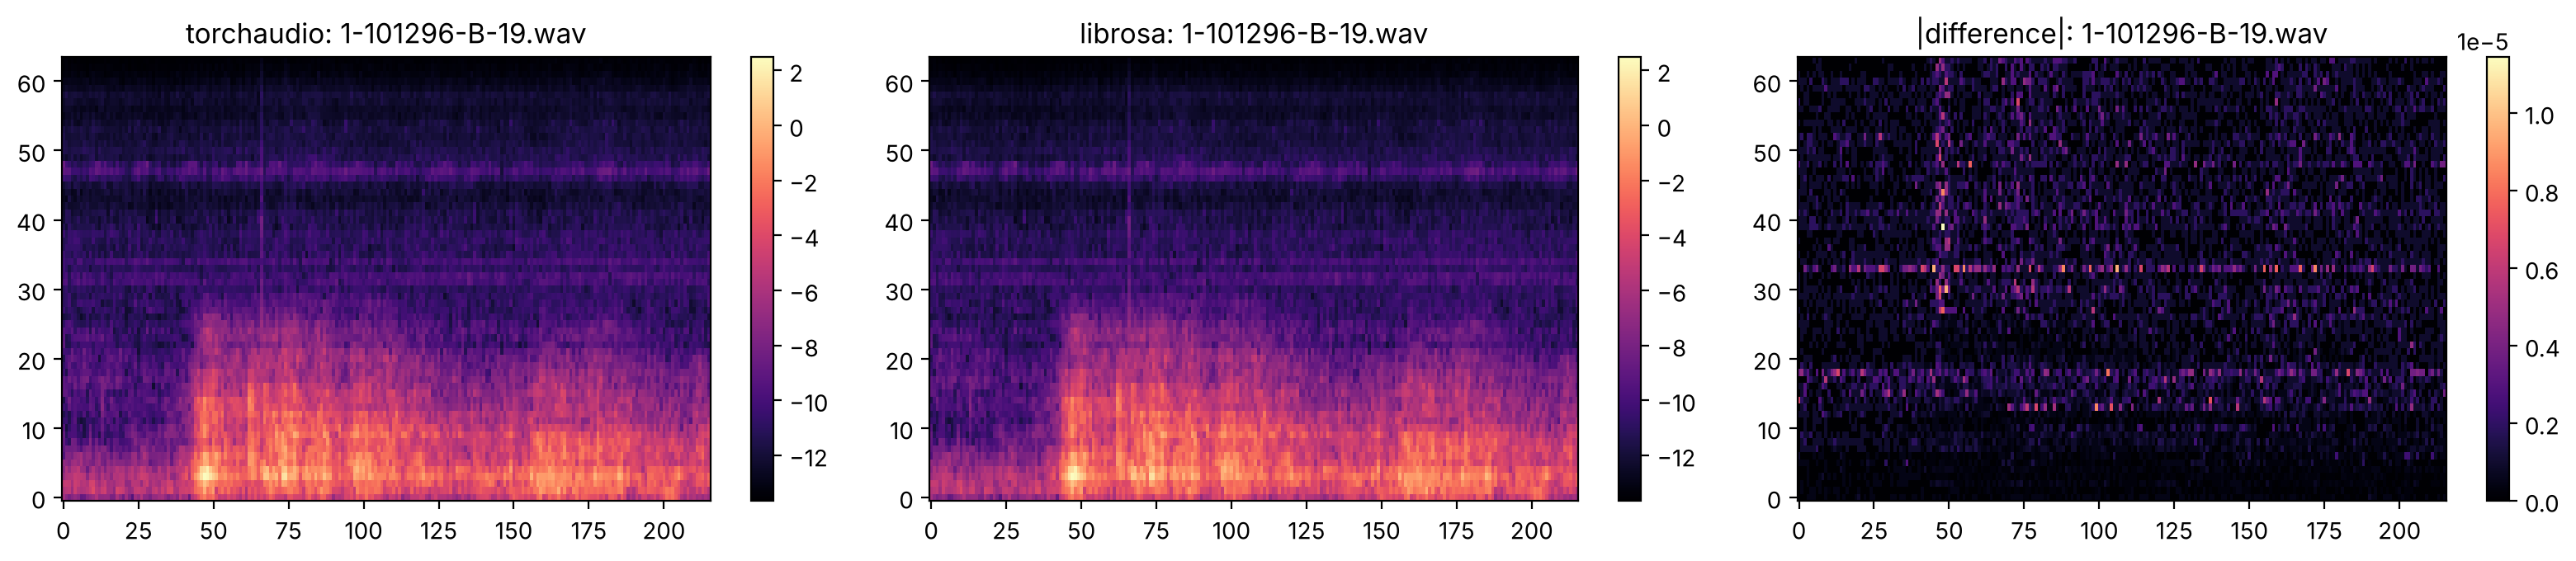

In [3]:
from audioscope.features import FeatureConfig, LogMel, fix_length, load_audio
from audioscope.config import load_config
from audioscope.data import load_esc50
cfg = FeatureConfig.from_dict(load_config("configs/baseline.yaml")["features"])
cat = load_esc50("data/esc50")
i = cat.filenames.index(res["clips"][0]["filename"])
wave = fix_length(load_audio(cat.paths[i], cfg.sample_rate)[0], cfg.num_samples)
ta = LogMel(cfg)(wave).numpy()
lr = feature_check.librosa_logmel(wave.numpy(), cfg)
fig, ax = plt.subplots(1, 3, figsize=(16, 3.5))
for a, img, t in zip(ax, [ta, lr, np.abs(ta - lr)], ["torchaudio", "librosa", "|difference|"]):
    im = a.imshow(img, origin="lower", aspect="auto", cmap="magma"); a.set_title(f"{t}: {cat.filenames[i]}"); fig.colorbar(im, ax=a)
fig.tight_layout()